<a href="https://colab.research.google.com/github/mahimakoulcs24/BIS-LAB/blob/main/BIS2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Iteration: 100 Best Fitness: 26.44
Iteration: 200 Best Fitness: 26.42
Iteration: 300 Best Fitness: 26.42
Iteration: 400 Best Fitness: 26.42
Iteration: 500 Best Fitness: 26.42

----- FINAL RESULT -----
Starting Point: [1. 1.]
Destination: [18. 18.]
Optimized Waypoints:
[[ 2.58  0.  ]
 [ 2.58  0.  ]
 [11.91  6.  ]
 [15.9  13.84]
 [17.39 16.8 ]]
Total Path Distance: 26.42
Path Status: Collision-Free


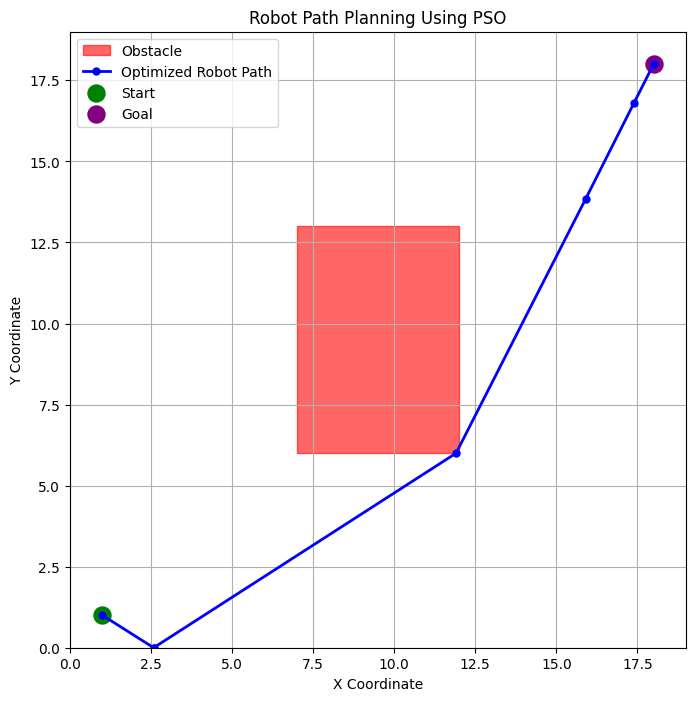

In [1]:

import numpy as np
import matplotlib.pyplot as plt

# --------------------------------
# 1. Define the environment
# --------------------------------

START = np.array([1.0, 1.0])
GOAL = np.array([18.0, 18.0])

# Obstacles: (xmin, ymin, xmax, ymax)
obstacles = [
    (7, 6, 12, 13)
]

GRID_MIN = 0
GRID_MAX = 19

# --------------------------------
# 2. PSO Parameters
# --------------------------------

NUM_PARTICLES = 80
MAX_ITERATIONS = 500

W = 0.7
C1 = 1.5
C2 = 1.5

NUM_WAYPOINTS = 5
DIM = NUM_WAYPOINTS * 2

COLLISION_PENALTY = 10000

np.random.seed(42)

# --------------------------------
# 3. Check obstacle collision
# --------------------------------

def is_inside_obstacle(point):

    x, y = point

    for xmin, ymin, xmax, ymax in obstacles:

        if (xmin <= x <= xmax and
            ymin <= y <= ymax):
            return True

    return False


def path_collision(path):

    collision_count = 0

    for i in range(len(path) - 1):

        p1 = path[i]
        p2 = path[i + 1]

        distance = np.linalg.norm(p2 - p1)

        steps = max(2, int(distance / 0.2))

        for t in np.linspace(0, 1, steps + 1):

            point = p1 + t * (p2 - p1)

            if is_inside_obstacle(point):
                collision_count += 1
                break

    return collision_count


# --------------------------------
# 4. Calculate path distance
# --------------------------------

def calculate_distance(path):

    distance = 0

    for i in range(len(path) - 1):

        distance += np.linalg.norm(
            path[i + 1] - path[i]
        )

    return distance


# --------------------------------
# 5. Fitness function
# --------------------------------

def fitness(position):

    waypoints = position.reshape(
        NUM_WAYPOINTS, 2
    )

    path = np.vstack([
        START,
        waypoints,
        GOAL
    ])

    distance = calculate_distance(path)

    collisions = path_collision(path)

    return distance + COLLISION_PENALTY * collisions


# --------------------------------
# 6. Initialize particles
# --------------------------------

particles = np.random.uniform(
    GRID_MIN,
    GRID_MAX,
    (NUM_PARTICLES, DIM)
)

velocities = np.random.uniform(
    -1, 1,
    (NUM_PARTICLES, DIM)
)

pbest = particles.copy()

pbest_fitness = np.array([
    fitness(p) for p in particles
])

best_index = np.argmin(pbest_fitness)

gbest = pbest[best_index].copy()

gbest_fitness = pbest_fitness[best_index]

# --------------------------------
# 7. PSO Optimization
# --------------------------------

for iteration in range(MAX_ITERATIONS):

    for i in range(NUM_PARTICLES):

        r1 = np.random.rand(DIM)
        r2 = np.random.rand(DIM)

        # Update velocity
        velocities[i] = (
            W * velocities[i]
            + C1 * r1 * (pbest[i] - particles[i])
            + C2 * r2 * (gbest - particles[i])
        )

        # Update position
        particles[i] += velocities[i]

        # Keep particles inside the grid
        particles[i] = np.clip(
            particles[i],
            GRID_MIN,
            GRID_MAX
        )

        # Evaluate fitness
        current_fitness = fitness(particles[i])

        # Update personal best
        if current_fitness < pbest_fitness[i]:

            pbest[i] = particles[i].copy()

            pbest_fitness[i] = current_fitness

    # Update global best
    best_index = np.argmin(pbest_fitness)

    if pbest_fitness[best_index] < gbest_fitness:

        gbest = pbest[best_index].copy()

        gbest_fitness = pbest_fitness[best_index]

    if (iteration + 1) % 100 == 0:

        print(
            "Iteration:", iteration + 1,
            "Best Fitness:", round(gbest_fitness, 2)
        )

# --------------------------------
# 8. Get optimized path
# --------------------------------

waypoints = gbest.reshape(NUM_WAYPOINTS, 2)

best_path = np.vstack([
    START,
    waypoints,
    GOAL
])

final_distance = calculate_distance(best_path)

collision_count = path_collision(best_path)

print("\n----- FINAL RESULT -----")

print("Starting Point:", START)
print("Destination:", GOAL)

print("Optimized Waypoints:")
print(np.round(waypoints, 2))

print("Total Path Distance:",
      round(final_distance, 2))

if collision_count == 0:
    print("Path Status: Collision-Free")
else:
    print("Path Status: Collision Detected")
    print("Try increasing the number of particles "
          "or iterations.")

# --------------------------------
# 9. Visualize the robot path
# --------------------------------

plt.figure(figsize=(9, 8))

# Draw obstacles
for xmin, ymin, xmax, ymax in obstacles:

    plt.fill(
        [xmin, xmax, xmax, xmin],
        [ymin, ymin, ymax, ymax],
        color="red",
        alpha=0.6,
        label="Obstacle"
    )

# Draw optimized path
plt.plot(
    best_path[:, 0],
    best_path[:, 1],
    "b-o",
    linewidth=2,
    markersize=5,
    label="Optimized Robot Path"
)

# Start and goal
plt.scatter(
    START[0], START[1],
    color="green",
    s=150,
    label="Start"
)

plt.scatter(
    GOAL[0], GOAL[1],
    color="purple",
    s=150,
    label="Goal"
)

plt.title("Robot Path Planning Using PSO")

plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")

plt.xlim(0, 19)
plt.ylim(0, 19)

plt.grid(True)
plt.legend()
plt.gca().set_aspect("equal", adjustable="box")

plt.show()
